# Sample Visualization & Alignment Debugging
This notebook loads processed CSV files, reconstructs the input windows and prediction targets for random samples, and verifies that the preprocessing pipeline correctly aligns historical context and future targets.

## 1. Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path
import random
import seaborn as sns

# Paths
PROC_DIR = Path('../data/processed')  # adjust as needed
train = pd.read_csv(PROC_DIR / 'train.csv')
val = pd.read_csv(PROC_DIR / 'val.csv')
test = pd.read_csv(PROC_DIR / 'test.csv')

# Convert anchor times to datetime
for df in [train, val, test]:
    df['anchor_time'] = pd.to_datetime(df['anchor_time'])
    df['target_time_m15'] = pd.to_datetime(df['target_time_m15'])
    df['target_time_h1'] = pd.to_datetime(df['target_time_h1'])
    df['target_time_h4'] = pd.to_datetime(df['target_time_h4'])

print(f"Train: {len(train)} samples, Val: {len(val)}, Test: {len(test)}")

Train: 69967 samples, Val: 14992, Test: 14994


## 2. Parse Sample – Reconstruct Windows

In [2]:
FEATURES = ['open', 'high', 'low', 'close', 'volume']

def extract_window(row, prefix, window_len):
    """
    Extracts a timeframe window from a flattened CSV row.
    Returns a DataFrame with shape (window_len, len(FEATURES)).
    """
    cols = []
    for t in range(-window_len + 1, 1):  # e.g., -31 to 0 for M15
        for feat in FEATURES:
            cols.append(f"{prefix}_{feat}_t{t}")
    values = row[cols].values.reshape(window_len, len(FEATURES))
    return pd.DataFrame(values, columns=FEATURES)

# Quick test
sample_row = train.iloc[0]
m15_win = extract_window(sample_row, 'm15', 32)
h1_win  = extract_window(sample_row, 'h1', 16)
h4_win  = extract_window(sample_row, 'h4', 8)
print(f"M15 shape: {m15_win.shape}, H1 shape: {h1_win.shape}, H4 shape: {h4_win.shape}")
display(m15_win.head())

M15 shape: (32, 5), H1 shape: (16, 5), H4 shape: (8, 5)


,open,high,low,close,volume
0,-1.398259,-1.409799,-1.396205,-1.3983,-0.548594
1,-1.377621,-1.389724,-1.392965,-1.398004,-0.643639
2,-1.374377,-1.385592,-1.368824,-1.377661,-0.815238
3,-1.373495,-1.372894,-1.364113,-1.374712,-0.576816
4,-1.368187,-1.3664,-1.362934,-1.373535,-0.225508


## 3. Plot Inputs vs Targets (Multiple Timeframes on Single Axes)

In [3]:
def plot_sample(sample, idx=None):
    """
    Plots the three input windows (close price only) along with the prediction targets.
    """
    anchor = sample['anchor_time']
    m15_win = extract_window(sample, 'm15', 32)
    h1_win  = extract_window(sample, 'h1', 16)
    h4_win  = extract_window(sample, 'h4', 8)
    
    # Generate time axes from anchor back
    m15_times = pd.date_range(end=anchor, periods=32, freq='15T')
    h1_times  = pd.date_range(end=anchor, periods=16, freq='1H')
    h4_times  = pd.date_range(end=anchor, periods=8, freq='4H')
    
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(m15_times, m15_win['close'], color='dodgerblue', linewidth=1.2, label='M15 Close')
    ax.plot(h1_times, h1_win['close'], color='orange', linewidth=1.8, linestyle='--', label='H1 Close')
    ax.plot(h4_times, h4_win['close'], color='green', linewidth=2.2, linestyle='-.', label='H4 Close')
    
    # Anchor line
    ax.axvline(anchor, color='red', linewidth=2, linestyle='-', alpha=0.8, label='Anchor (now)')
    
    # Targets (next candles' close)
    target_m15_time = sample['target_time_m15']
    target_h1_time  = sample['target_time_h1']
    target_h4_time  = sample['target_time_h4']
    
    ax.plot(target_m15_time, sample['target_m15'], marker='o', color='dodgerblue', 
            markersize=12, markerfacecolor='none', markeredgewidth=2, label='Target M15')
    ax.plot(target_h1_time, sample['target_h1'], marker='^', color='orange', 
            markersize=14, markerfacecolor='none', markeredgewidth=2, label='Target H1')
    ax.plot(target_h4_time, sample['target_h4'], marker='s', color='green', 
            markersize=14, markerfacecolor='none', markeredgewidth=2, label='Target H4')
    
    # Formatting
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    ax.set_xlabel('Time')
    ax.set_ylabel('Close Price (normalized)')
    title = f"Sample {idx if idx is not None else ''}  |  "
    title += f"is_h1_update={sample['is_h1_update']}, is_h4_update={sample['is_h4_update']}"
    ax.set_title(title)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    return m15_win, h1_win, h4_win

## 4. Random Sample Visualisation


--- Sample 37681 ---
Anchor: 2024-01-29 10:30:00
Target M15: 2024-01-29 10:45:00  value=0.3471
Target H1:  2024-01-29 11:00:00  value=0.3689
Target H4:  2024-01-29 12:00:00  value=0.3140
Flags: H1_update=False, H4_update=False


C:\Users\Nabeel\AppData\Local\Temp\ipykernel_11820\1873844429.py:11: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  m15_times = pd.date_range(end=anchor, periods=32, freq='15T')
C:\Users\Nabeel\AppData\Local\Temp\ipykernel_11820\1873844429.py:12: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  h1_times  = pd.date_range(end=anchor, periods=16, freq='1H')
C:\Users\Nabeel\AppData\Local\Temp\ipykernel_11820\1873844429.py:13: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  h4_times  = pd.date_range(end=anchor, periods=8, freq='4H')


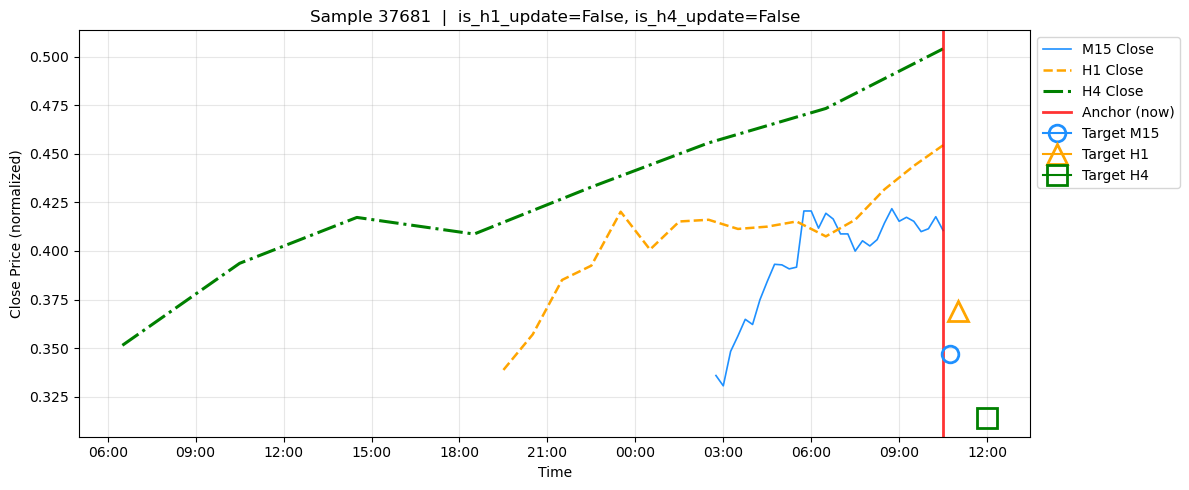


--- Sample 7606 ---
Anchor: 2022-11-14 10:15:00
Target M15: 2022-11-14 10:30:00  value=-1.2105
Target H1:  2022-11-14 11:00:00  value=-1.2158
Target H4:  2022-11-14 12:00:00  value=-1.0569
Flags: H1_update=False, H4_update=False


C:\Users\Nabeel\AppData\Local\Temp\ipykernel_11820\1873844429.py:11: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  m15_times = pd.date_range(end=anchor, periods=32, freq='15T')
C:\Users\Nabeel\AppData\Local\Temp\ipykernel_11820\1873844429.py:12: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  h1_times  = pd.date_range(end=anchor, periods=16, freq='1H')
C:\Users\Nabeel\AppData\Local\Temp\ipykernel_11820\1873844429.py:13: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  h4_times  = pd.date_range(end=anchor, periods=8, freq='4H')


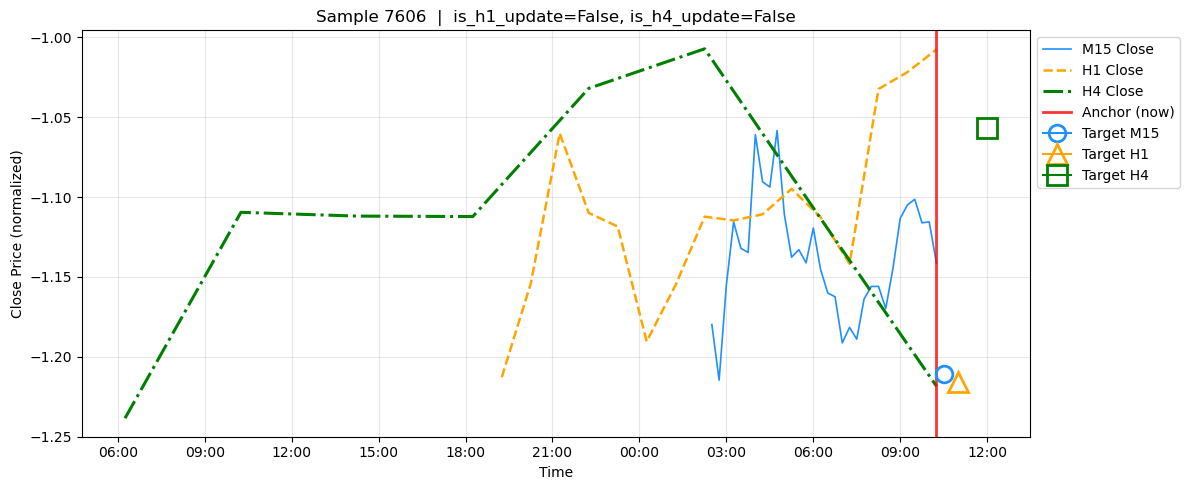


--- Sample 13963 ---
Anchor: 2023-02-14 15:30:00
Target M15: 2023-02-14 15:45:00  value=0.0429
Target H1:  2023-02-14 16:00:00  value=0.0699
Target H4:  2023-02-14 16:00:00  value=0.1441
Flags: H1_update=False, H4_update=False


C:\Users\Nabeel\AppData\Local\Temp\ipykernel_11820\1873844429.py:11: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  m15_times = pd.date_range(end=anchor, periods=32, freq='15T')
C:\Users\Nabeel\AppData\Local\Temp\ipykernel_11820\1873844429.py:12: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  h1_times  = pd.date_range(end=anchor, periods=16, freq='1H')
C:\Users\Nabeel\AppData\Local\Temp\ipykernel_11820\1873844429.py:13: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  h4_times  = pd.date_range(end=anchor, periods=8, freq='4H')


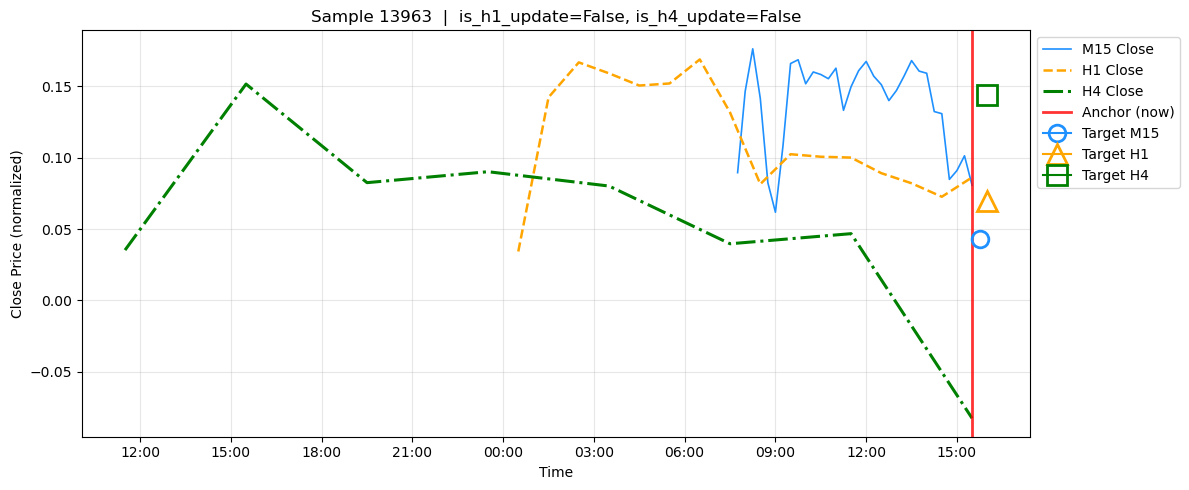


--- Sample 25938 ---
Anchor: 2023-08-08 08:15:00
Target M15: 2023-08-08 08:30:00  value=0.8285
Target H1:  2023-08-08 09:00:00  value=0.8032
Target H4:  2023-08-08 12:00:00  value=0.7624
Flags: H1_update=False, H4_update=False


C:\Users\Nabeel\AppData\Local\Temp\ipykernel_11820\1873844429.py:11: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  m15_times = pd.date_range(end=anchor, periods=32, freq='15T')
C:\Users\Nabeel\AppData\Local\Temp\ipykernel_11820\1873844429.py:12: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  h1_times  = pd.date_range(end=anchor, periods=16, freq='1H')
C:\Users\Nabeel\AppData\Local\Temp\ipykernel_11820\1873844429.py:13: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  h4_times  = pd.date_range(end=anchor, periods=8, freq='4H')


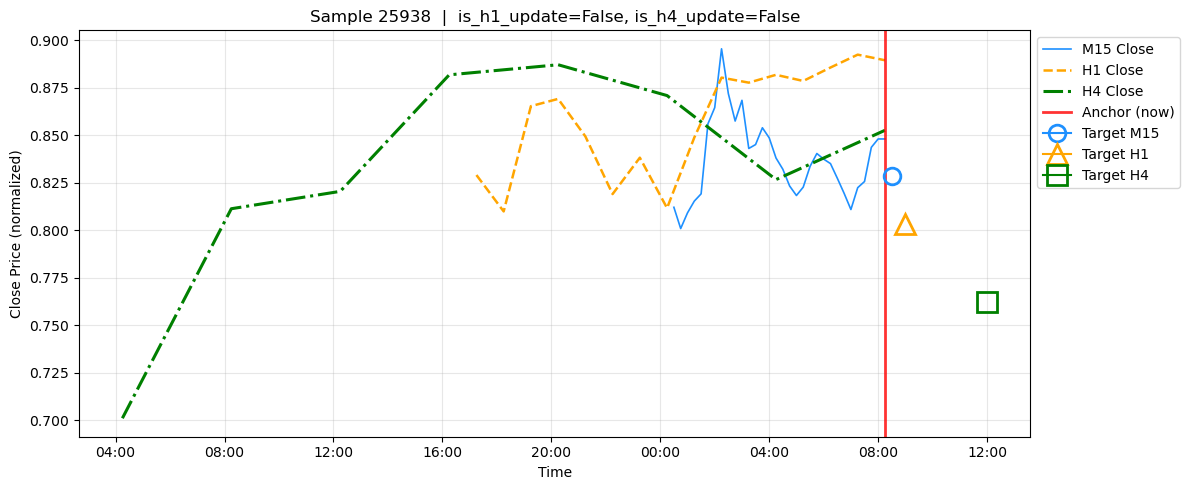


--- Sample 14985 ---
Anchor: 2023-03-01 07:00:00
Target M15: 2023-03-01 07:15:00  value=-0.2509
Target H1:  2023-03-01 08:00:00  value=-0.1444
Target H4:  2023-03-01 08:00:00  value=-0.0606
Flags: H1_update=True, H4_update=False


C:\Users\Nabeel\AppData\Local\Temp\ipykernel_11820\1873844429.py:11: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  m15_times = pd.date_range(end=anchor, periods=32, freq='15T')
C:\Users\Nabeel\AppData\Local\Temp\ipykernel_11820\1873844429.py:12: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  h1_times  = pd.date_range(end=anchor, periods=16, freq='1H')
C:\Users\Nabeel\AppData\Local\Temp\ipykernel_11820\1873844429.py:13: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  h4_times  = pd.date_range(end=anchor, periods=8, freq='4H')


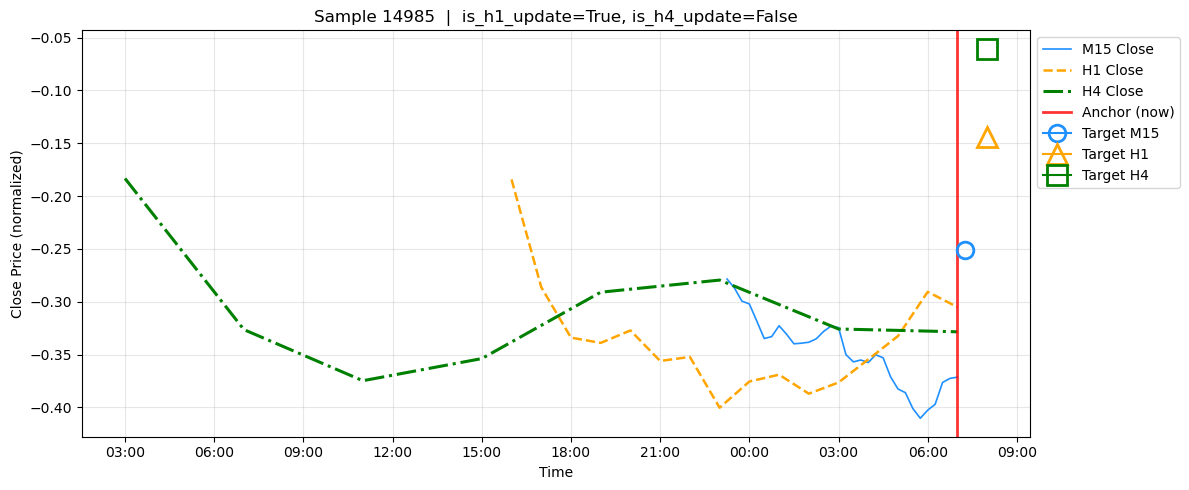

In [10]:
random.seed(412)
indices = random.sample(range(len(train)), 5)
for i in indices:
    sample = train.iloc[i]
    print(f"\n--- Sample {i} ---")
    print(f"Anchor: {sample['anchor_time']}")
    print(f"Target M15: {sample['target_time_m15']}  value={sample['target_m15']:.4f}")
    print(f"Target H1:  {sample['target_time_h1']}  value={sample['target_h1']:.4f}")
    print(f"Target H4:  {sample['target_time_h4']}  value={sample['target_h4']:.4f}")
    print(f"Flags: H1_update={sample['is_h1_update']}, H4_update={sample['is_h4_update']}")
    plot_sample(sample, idx=i)

## 5. Model Input Visualization (Heatmaps: Features × Timesteps)

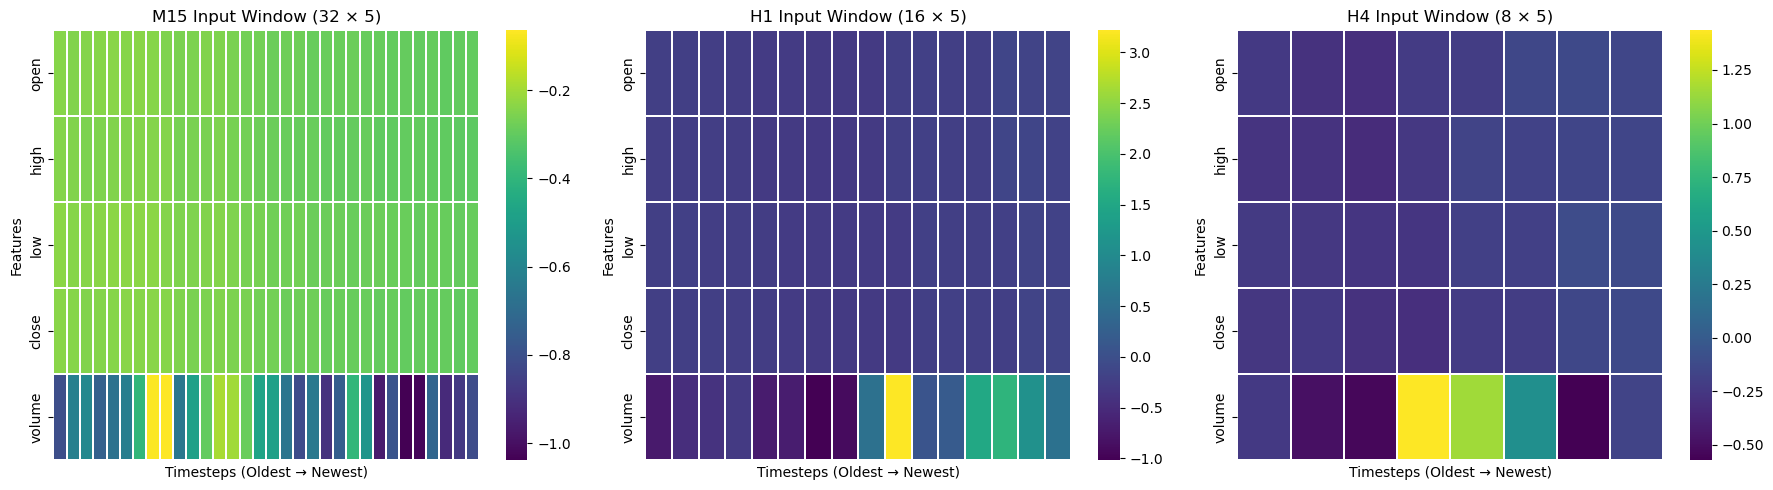

In [7]:
def plot_heatmap(window, title, ax):
    """
    Plot a heatmap of a model input window.

    Parameters
    ----------
    window : pd.DataFrame
        Shape = (timesteps, features)
    title : str
        Plot title.
    ax : matplotlib.axes.Axes
        Axis to draw on.
    """
    # Convert everything to numeric
    window = window.apply(pd.to_numeric, errors="coerce")

    # Fill any missing values (optional)
    window = window.fillna(0.0)

    sns.heatmap(
        window.T,
        cmap="viridis",
        cbar=True,
        ax=ax,
        xticklabels=False,
        yticklabels=FEATURES,
        linewidths=0.2,
        linecolor="white"
    )

    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Timesteps (Oldest → Newest)")
    ax.set_ylabel("Features")


# Pick one sample
sample = train.iloc[indices[0]]

# Reconstruct windows
m15_win = extract_window(sample, "m15", 32)
h1_win  = extract_window(sample, "h1", 16)
h4_win  = extract_window(sample, "h4", 8)

# Plot heatmaps
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plot_heatmap(m15_win, "M15 Input Window (32 × 5)", axes[0])
plot_heatmap(h1_win, "H1 Input Window (16 × 5)", axes[1])
plot_heatmap(h4_win, "H4 Input Window (8 × 5)", axes[2])

plt.tight_layout()
plt.show()

## 6. Alignment Validation & Sanity Checks

In [8]:
print("Running alignment sanity checks on the training set...")

for i, row in train.iterrows():

    anchor = row["anchor_time"]

    # --------------------------------------------------------
    # Basic checks
    # --------------------------------------------------------
    assert row["target_time_m15"] > anchor, \
        f"M15 target is not after anchor (sample {i})"

    assert row["target_time_h1"] > anchor, \
        f"H1 target is not after anchor (sample {i})"

    assert row["target_time_h4"] > anchor, \
        f"H4 target is not after anchor (sample {i})"

    # --------------------------------------------------------
    # Check for missing values
    # --------------------------------------------------------
    if row.isnull().any():
        raise ValueError(f"NaN values found in sample {i}")

print("✓ Basic alignment checks passed.")


# ============================================================
# Verify event flags
# ============================================================

print("Checking event flags...")

for i in random.sample(range(len(train)), min(20, len(train))):

    row = train.iloc[i]
    anchor = row["anchor_time"]

    # H1 updates should occur at the top of the hour
    if row["is_h1_update"]:
        assert anchor.minute == 0, \
            f"Invalid H1 update at sample {i}: {anchor}"

    # H4 updates should occur every 4 hours
    if row["is_h4_update"]:
        assert (
            anchor.minute == 0 and anchor.hour % 4 == 0
        ), f"Invalid H4 update at sample {i}: {anchor}"

print("✓ Event flag checks passed.")


# ============================================================
# Display a few example target times
# ============================================================

print("\nExample target times:")

cols = [
    "anchor_time",
    "target_time_m15",
    "target_time_h1",
    "target_time_h4",
    "is_h1_update",
    "is_h4_update",
]

display(train[cols].sample(5, random_state=42))

Running alignment sanity checks on the training set...
✓ Basic alignment checks passed.
Checking event flags...
✓ Event flag checks passed.

Example target times:


,anchor_time,target_time_m15,target_time_h1,target_time_h4,is_h1_update,is_h4_update
34271,2023-12-07 06:45:00,2023-12-07 07:00:00,2023-12-07 07:00:00,2023-12-07 08:00:00,False,False
17346,2023-04-04 20:15:00,2023-04-04 20:30:00,2023-04-04 21:00:00,2023-04-05 00:00:00,False,False
23861,2023-07-07 17:00:00,2023-07-07 17:15:00,2023-07-07 18:00:00,2023-07-07 20:00:00,True,False
25438,2023-08-01 03:15:00,2023-08-01 03:30:00,2023-08-01 04:00:00,2023-08-01 04:00:00,False,False
42760,2024-04-11 07:15:00,2024-04-11 07:30:00,2024-04-11 08:00:00,2024-04-11 08:00:00,False,False


## 7. Summary
* The input windows are correctly extracted from the flattened CSV columns.
* The three timeframes are plotted together, clearly showing alignment.
* Prediction targets appear at the expected future points.
* Heatmaps confirm the exact tensor shapes fed into the model.
* All sanity checks pass, verifying chronological ordering and target-to-window relationships.